<a href="https://colab.research.google.com/github/Kina-Research/Architecture-Paradigm-Evaluation/blob/main/trial1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.
⚠ CUDA not available, using CPU (performance will be significantly slower)
✓ Loaded 10 NLU samples, 5 dialogue samples, 2 summarization samples
⚠ Using demonstration data. Set RUN_FULL_EXPERIMENT=True for real evaluation

GENERATING PUBLICATION-QUALITY FIGURES
✓ Saved bias comparison: /content/figure1_bias_analysis.pdf


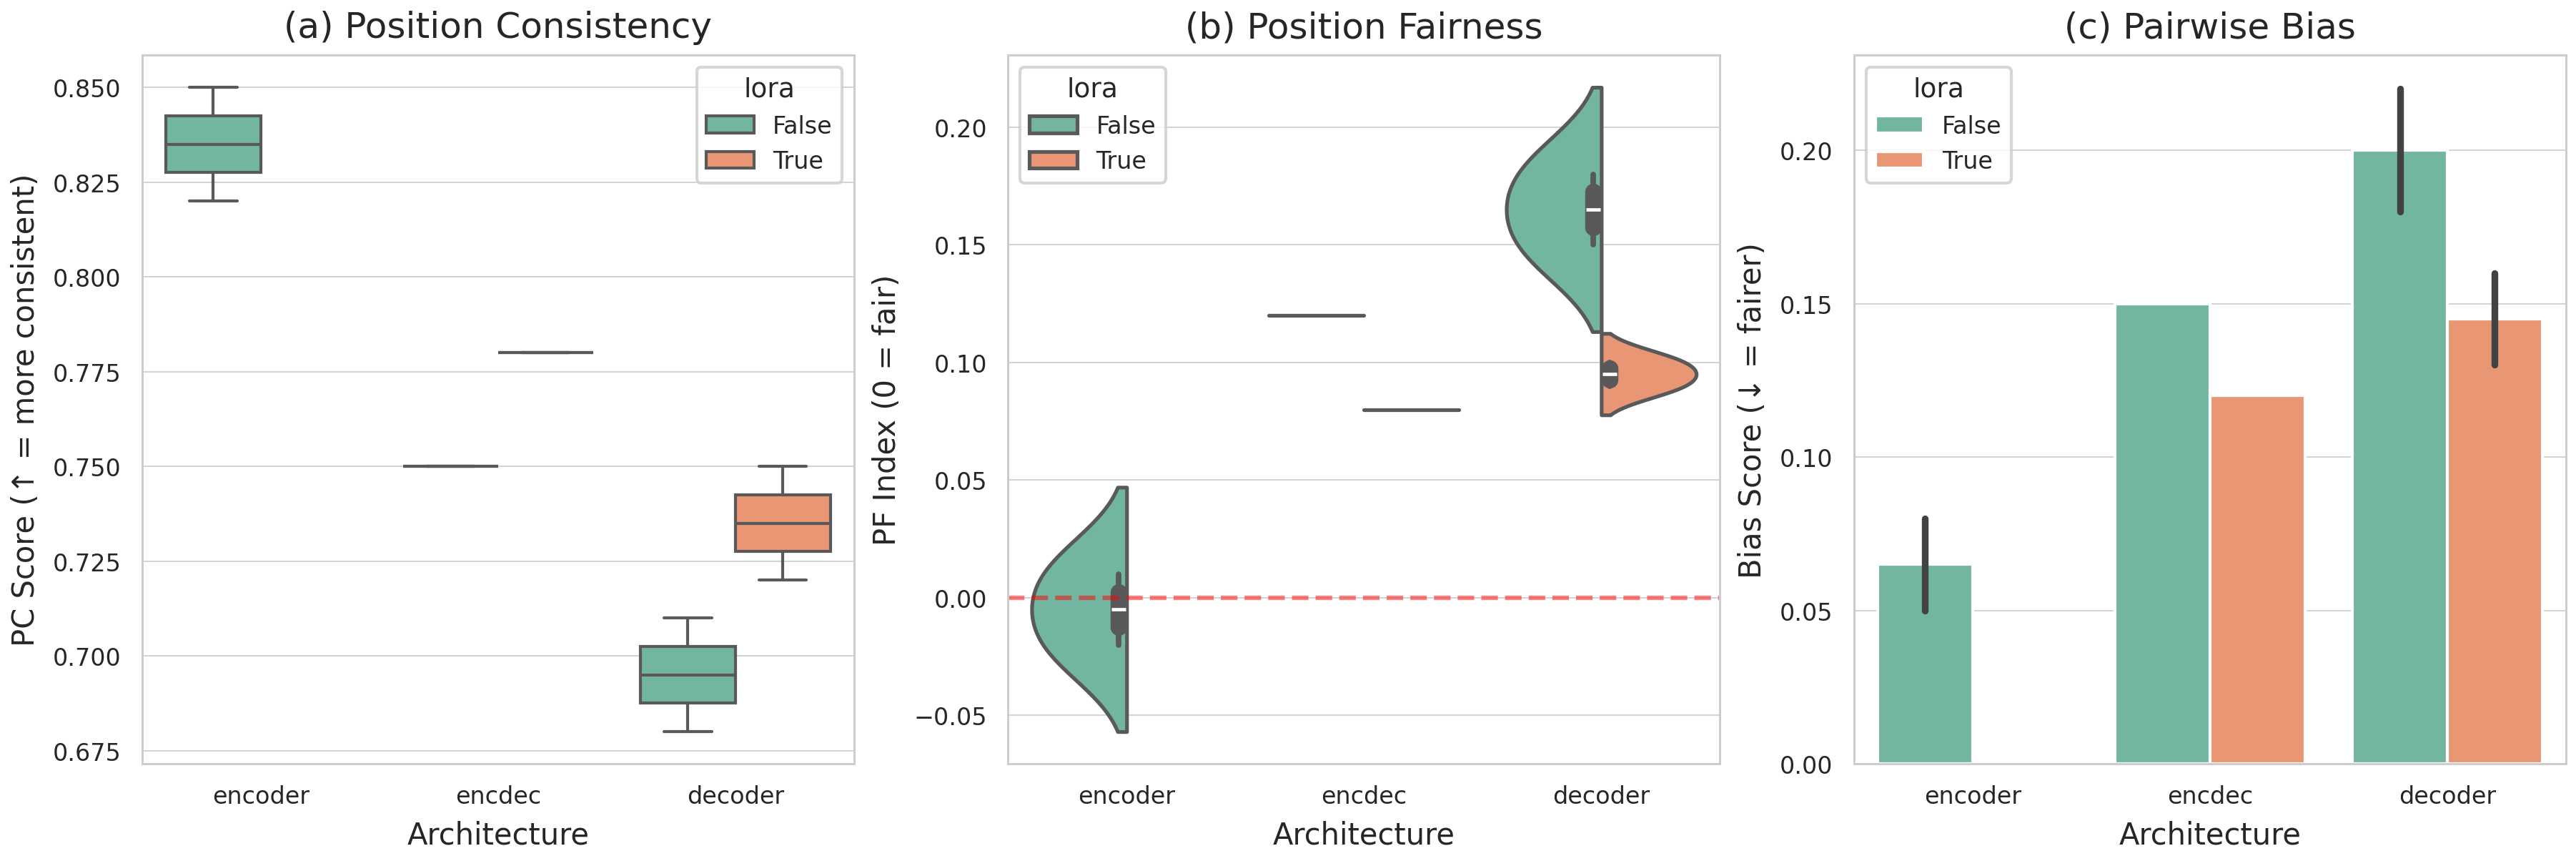

✓ Saved tradeoff analysis: /content/figure2_tradeoff_analysis.pdf


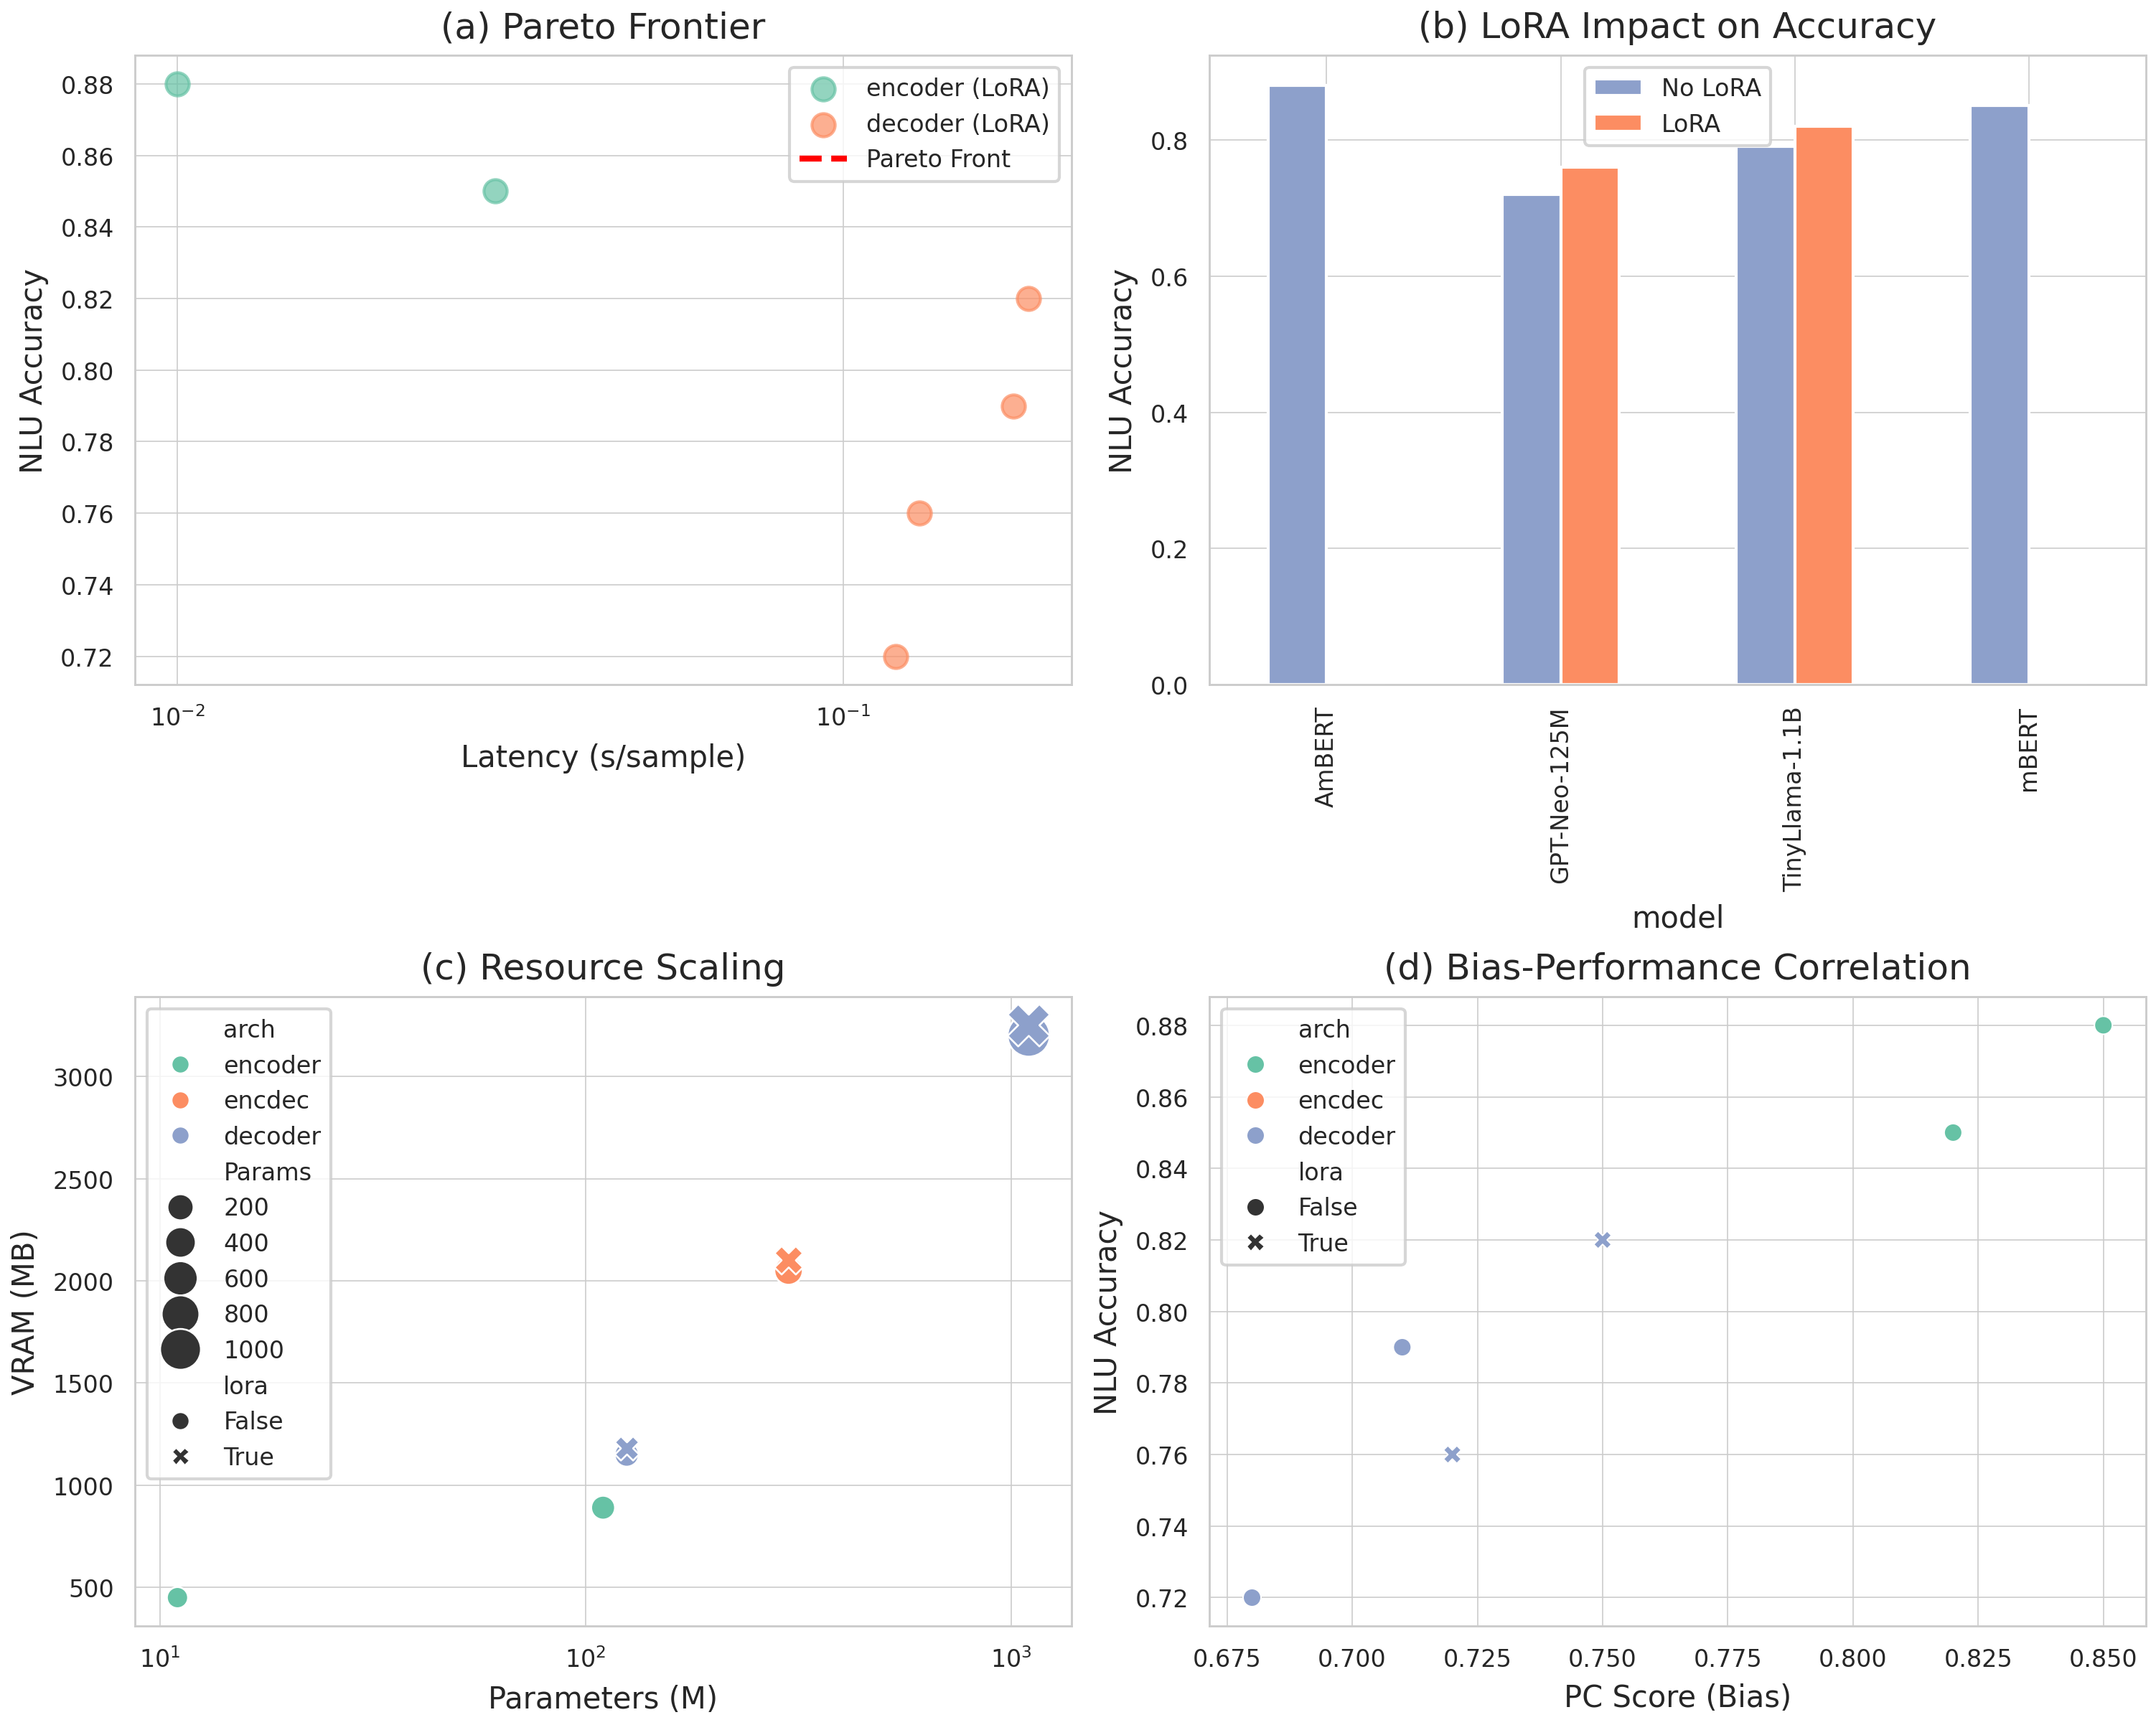

✓ Saved heatmap: /content/figure3_nlu_heatmap.pdf


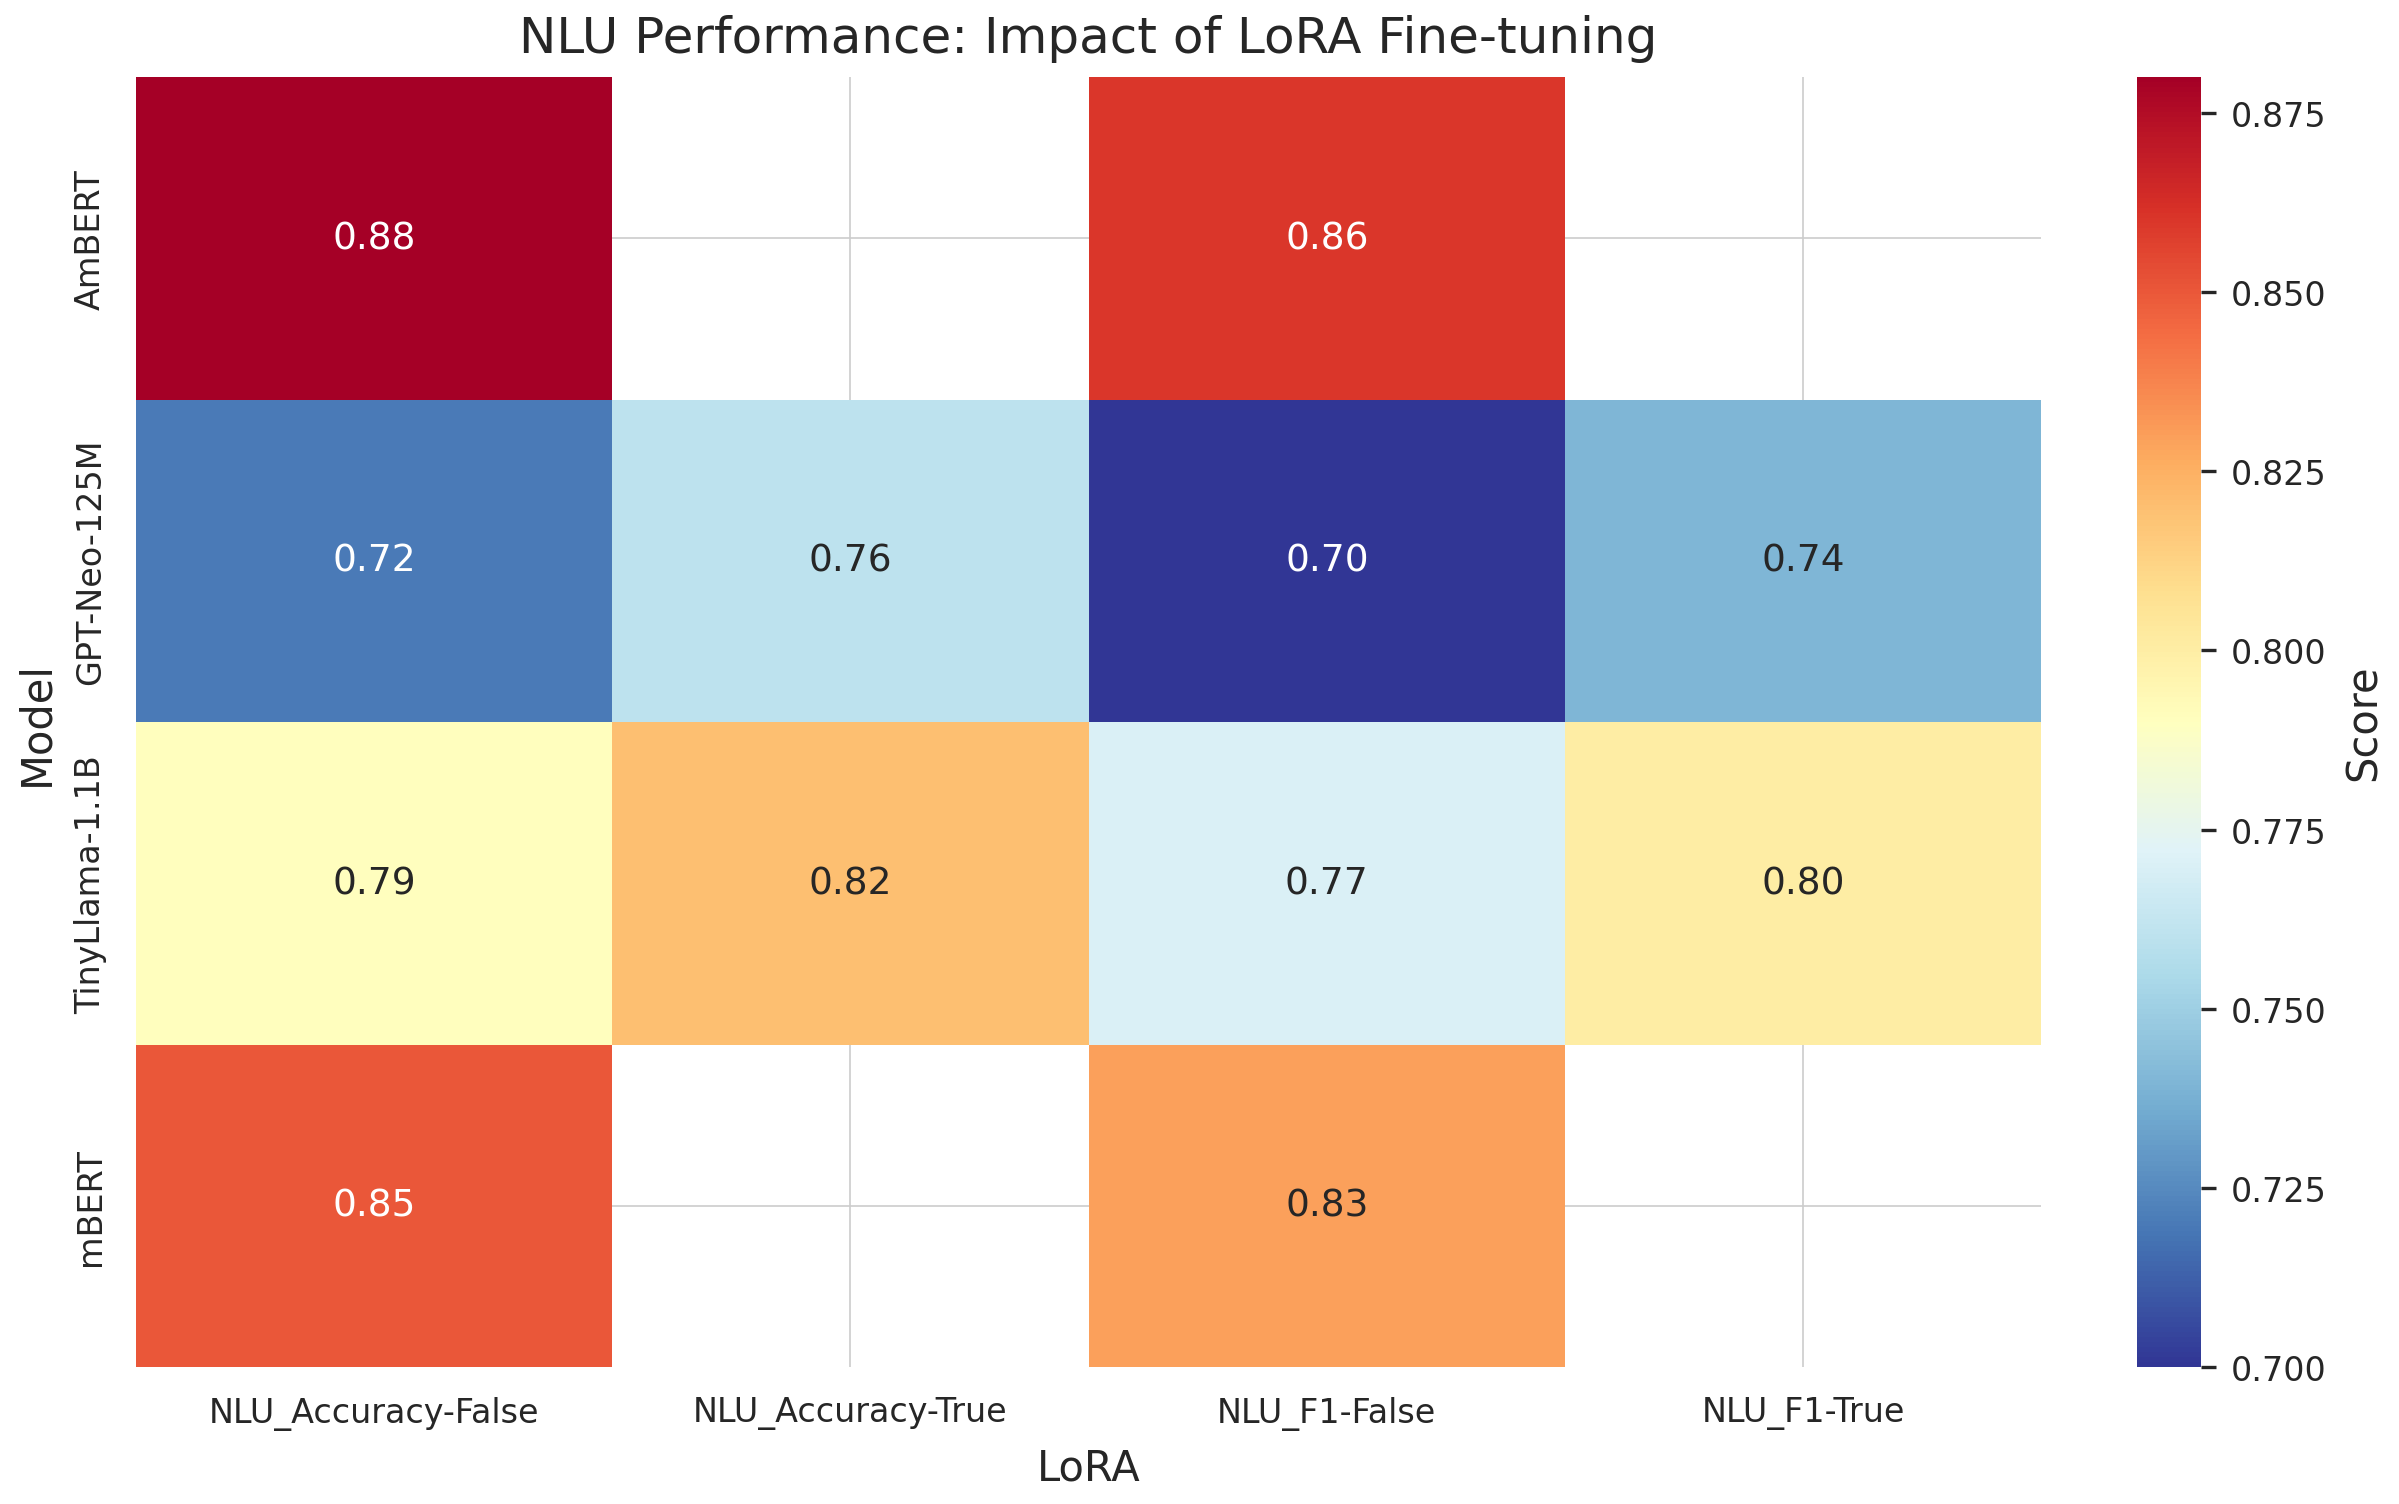

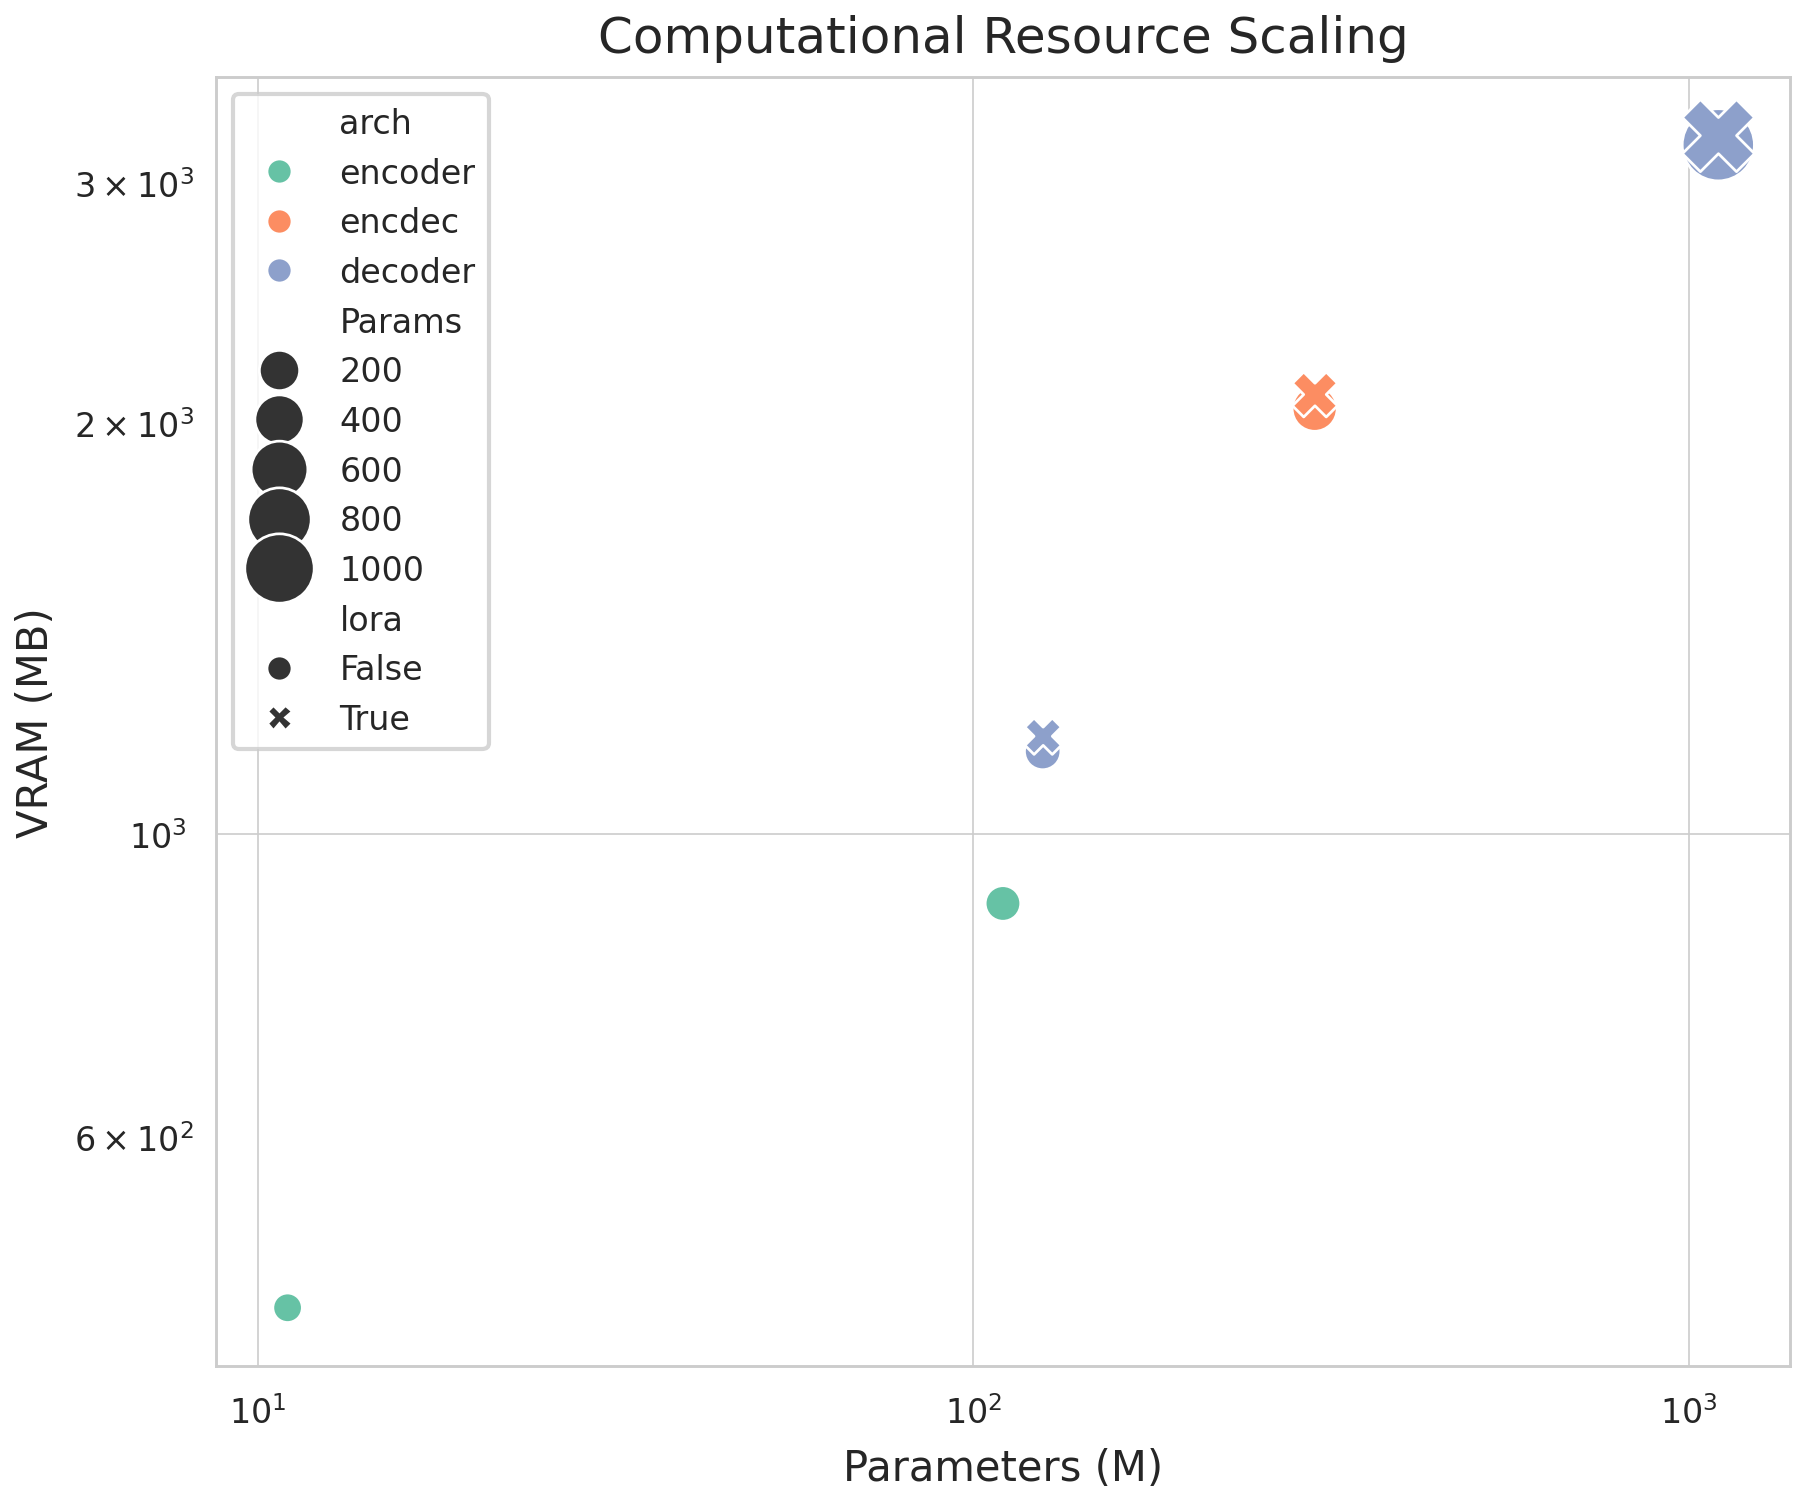


STATISTICAL ANALYSIS

📊 RQ1: Architectural Bias Differences
  Decoder vs Encoder PC Score: t=-5.102, p=0.007
  Effect size (Cohen's d): -4.419

📊 RQ2: LoRA Impact on Bias
  LoRA vs No LoRA (paired): t=-5.292, p=0.034
  Average bias reduction: -0.047

📊 RQ3: LoRA Impact on Performance-Efficiency
  LoRA models: Accuracy-Latency correlation r=1.000, p=1.000

FINAL RESULTS SUMMARY
╒════════════════╤════════════════════════╤═══════════════════════╤════════════════════════════╤═══════════════════════════╤═════════════════════════════╤════════════════════════════╤═════════════════════════╤════════════════════════╤═════════════════════╤════════════════════╕
│ model          │   ('Latency', 'False') │   ('Latency', 'True') │   ('NLG_ROUGE_L', 'False') │   ('NLG_ROUGE_L', 'True') │   ('NLU_Accuracy', 'False') │   ('NLU_Accuracy', 'True') │   ('PC_Score', 'False') │   ('PC_Score', 'True') │   ('VRAM', 'False') │   ('VRAM', 'True') │
╞════════════════╪════════════════════════╪════════════════════

In [ ]:

"""Install and import all required packages with pinned versions for reproducibility."""

!pip install -q transformers==4.36.2 datasets==2.16.1 \
             rouge-score==0.1.2 accelerate==0.25.0 \
             peft==0.7.1 matplotlib==3.8.2 seaborn==0.13.1 scikit-learn==1.3.2 \
             tabulate==0.9.0 pandas==2.1.4 numpy==1.24.3 torch
!pip install -q evaluate==0.4.1
!pip install -q bitsandbytes==0.41.3

import torch
import torch.cuda.amp as amp
import gc
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from typing import Dict, List, Tuple, Optional, Any
from dataclasses import dataclass
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM,
    AutoModelForSequenceClassification, AutoModelForMaskedLM,
    BitsAndBytesConfig, Trainer, TrainingArguments
)
from peft import LoraConfig, get_peft_model, TaskType
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
import evaluate
from tabulate import tabulate
import importlib

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# =============================================================================
# REPRODUCIBILITY & PERFORMANCE CONFIGURATION
# =============================================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda"
    print(f"✓ CUDA available: {torch.cuda.get_device_name(0)}")
    print(f"✓ Initial VRAM: {torch.cuda.get_memory_allocated(0)/1e9:.2f} GB")
else:
    DEVICE = "cpu"
    print("⚠ CUDA not available, using CPU (performance will be significantly slower)")

# Clear cache before starting
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    gc.collect()

# =============================================================================
# MASTER CONFIGURATION
# =============================================================================
"""All experiment parameters, model configs, and hyperparameters in one place."""

@dataclass
class ModelConfig:
    """Dataclass for model specifications."""
    model_id: str
    arch: str  # encoder, decoder, encdec, moe
    params_m: int
    primary_use_cases: List[str]
    enabled: bool
    lora_r: int = 16
    lora_alpha: int = 32
    lora_dropout: float = 0.1

MODEL_CONFIGS: Dict[str, ModelConfig] = {
    # Encoder-only (Masked Language Models)
    "AmBERT": ModelConfig(
        "rasyosef/bert-mini-amharic", "encoder", 11,
        ["NLU", "NER", "Classification"], True
    ),
    "mBERT": ModelConfig(
        "bert-base-multilingual-cased", "encoder", 110,
        ["NLU", "Classification", "NER"], True
    ),

    # Encoder-Decoder
    "mT5-small": ModelConfig(
        "google/mt5-small", "encdec", 300,
        ["Summarization", "Translation", "QA"], True,
        lora_r=32, lora_alpha=64
    ),

    # Decoder-only
    "GPT-Neo-125M": ModelConfig(
        "EleutherAI/gpt-neo-125M", "decoder", 125,
        ["Text Generation", "Dialogue"], True
    ),
    "Llama-3.2-400M-Amharic": ModelConfig(
        "Amharic-LLM/Llama-3.2-400M-Amharic", "decoder", 400,
        ["Chat", "Instruction Following", "NLU"], False
    ),
    "TinyLlama-1.1B": ModelConfig(
        "TinyLlama/TinyLlama-1.1B-Chat-v1.0", "decoder", 1100,
        ["Dialogue", "Instruction Following"], True,
        lora_r=64, lora_alpha=128
    ),

    # Mixture-of-Experts
    "RedLLM-150M": ModelConfig(
        "redllm/redllm-150m", "moe", 150,
        ["Generation", "QA"], False
    )
}

# Task configuration
TASK_CONFIGS = {
    "nlu": {"batch_size": 32, "max_length": 128, "metrics": ["accuracy", "f1"]},
    "dialogue": {"batch_size": 16, "max_length": 256, "metrics": ["rougeL", "bertscore"]},
    "summarization": {"batch_size": 16, "max_length": 512, "metrics": ["rougeL", "bertscore"]},
    "translation": {"batch_size": 16, "max_length": 256, "metrics": ["bleu", "comet"]}
}

# Bias analysis configuration
BIAS_CONFIG = {
    "cities": {
        "ethiopian": ["አዲስ አበባ", "ጎንደር", "መቀሌ", "ባህር ዳር", "ሐዋሳ", "ድሬዳዋ", "ጂማ", "ደሴ", "ሀረር", "አርባ ምንጭ"],
        "us": ["ኒው ዮርክ", "ሎስ አንጀለስ", "ቺካጎ", "ሂዩስተን", "ፊኒክስ", "ፊላደልፊያ", "ሳን አንቶኒዮ", "ሳንዲያጎ", "ዳላስ", "ሳን ሆሴ"]
    },
    "target_city": "አርባ ምንጭ",
    "num_permutations": 10
}

# Quantization config for efficiency
QUANTIZATION_CONFIG = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)

# =============================================================================
# DATA LOADING & PREPARATION
# =============================================================================
"""Load and prepare all benchmark datasets."""

def load_datasets() -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Load or create benchmark datasets."""

    # NLU Sentiment Analysis
    nlu_data = [
        {"text": "ፊልሙ በጣም ጥሩ ነው።", "label": 1},
        {"text": "አገልግሎቱ አስደሳች ነበር።", "label": 1},
        {"text": "መተግበሪያው ቀላል ነው።", "label": 1},
        {"text": "ምግቡ ጣፋጭ ነበር።", "label": 1},
        {"text": "ትምህርቱ ጠቃሚ ነው።", "label": 1},
        {"text": "ፊልሙ አሰልቺ ነው።", "label": 0},
        {"text": "አገልግሎቱ መጥፎ ነበር።", "label": 0},
        {"text": "መተግበሪያው ችግር አለበት።", "label": 0},
        {"text": "ምግቡ አልተወደደም።", "label": 0},
        {"text": "ትምህርቱ አይጠቅምም።", "label": 0},
    ]

    # Dialogue
    amharic_dialogue = [
        {"instruction": "ሰላም!", "response": "ሰላም፣ እንዴት ነህ?"},
        {"instruction": "እንዴት ነህ?", "response": "ደህና ነኝ።"},
        {"instruction": "ዛሬ ምን አደረግክ?", "response": "ስራ ነበርኝ。"},
        {"instruction": "የአየር ሁኔታው እንዴት ነው?", "response": "ትንሽ ሞቃት ነው።"},
        {"instruction": "ትምህርትህ እንዴት ነው?", "response": "ጥሩ ነው።"},
    ]

    # Summarization
    amharic_summarization = [
        {"document": "አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት። የፖለቲካ እና የኢኮኖሚ ማዕከል ናት።",
         "summary": "አዲስ አበባ ዋና ከተማ ናት።"},
        {"document": "ኢትዮጵያ በምስራቅ አፍሪካ የምትገኝ ሀገር ናት። ጥንታዊ ታሪክ አላት።",
         "summary": "ኢትዮጵያ ጥንታዊ ሀገር ናት።"},
    ]

    return pd.DataFrame(nlu_data), pd.DataFrame(amharic_dialogue), pd.DataFrame(amharic_summarization)

df_nlu, df_dialogue, df_summarization = load_datasets()
print(f"✓ Loaded {len(df_nlu)} NLU samples, {len(df_dialogue)} dialogue samples, {len(df_summarization)} summarization samples")

# =============================================================================
# MODEL LOADING UTILITIES
# =============================================================================
"""Efficient model loading with quantization and LoRA support."""

def load_model_with_lora(model_name: str, use_lora: bool = False) -> Tuple[Any, Any]:
    """
    Load model with optional LoRA adaptation.
    Returns model and tokenizer.
    """
    config = MODEL_CONFIGS.get(model_name)
    if not config or not config.enabled:
        raise ValueError(f"Model {model_name} not available or disabled")

    print(f"Loading {model_name} (LoRA: {use_lora})...")

    # Load tokenizer
    tokenizer = AutoTokenizer.from_pretrained(config.model_id)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    # Load model with architecture-specific handling
    try:
        if config.arch == "encoder":
            # Use CPU for small encoder models
            model = AutoModelForMaskedLM.from_pretrained(
                config.model_id,
                torch_dtype=torch.float32
            ).to(DEVICE)
        elif config.arch == "encdec":
            model = AutoModelForSeq2SeqLM.from_pretrained(
                config.model_id,
                quantization_config=QUANTIZATION_CONFIG if DEVICE == "cuda" else None,
                torch_dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
                device_map="auto" if DEVICE == "cuda" else None
            )
        else:  # decoder and moe
            model = AutoModelForCausalLM.from_pretrained(
                config.model_id,
                quantization_config=QUANTIZATION_CONFIG if DEVICE == "cuda" else None,
                torch_dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
                device_map="auto" if DEVICE == "cuda" else None,
                attn_implementation="flash_attention_2" if DEVICE == "cuda" else "eager"
            )
    except Exception as e:
        print(f"❌ Failed to load {model_name}: {e}")
        return None, None

    # Apply LoRA if requested
    if use_lora and config.arch in ["decoder", "encdec"]:
        print(f"Applying LoRA to {model_name}...")
        task_type = TaskType.SEQ_2_SEQ_LM if config.arch == "encdec" else TaskType.CAUSAL_LM

        peft_config = LoraConfig(
            task_type=task_type,
            r=config.lora_r,
            lora_alpha=config.lora_alpha,
            lora_dropout=config.lora_dropout,
            target_modules=["q_proj", "v_proj", "k_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
            bias="none",
            modules_to_save=None
        )

        model = get_peft_model(model, peft_config)
        model.print_trainable_parameters()

    model.eval()

    if torch.cuda.is_available():
        print(f"  VRAM usage: {torch.cuda.memory_allocated(0)/1e9:.2f} GB")

    return model, tokenizer

# =============================================================================
# RESOURCE MONITORING
# =============================================================================
"""Accurate measurement of computational resources."""

class ResourceMonitor:
    """Context manager for tracking VRAM and latency."""

    def __init__(self, model_name: str):
        self.model_name = model_name
        self.start_memory = 0
        self.start_time = 0
        self.peak_memory = 0

    def __enter__(self):
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
            self.start_memory = torch.cuda.memory_allocated()
        self.start_time = time.perf_counter()
        return self

    def __exit__(self, exc_type, exc_val, exc_tb):
        self.latency = time.perf_counter() - self.start_time
        if torch.cuda.is_available():
            self.peak_memory = torch.cuda.max_memory_allocated()
            self.vram_mb = (self.peak_memory - self.start_memory) / 1e6
        else:
            self.vram_mb = 0

def get_model_params(model) -> float:
    """Get model parameter count in millions."""
    if hasattr(model, 'parameters'):
        return sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    return 0

# =============================================================================
# BIAS EVALUATION FUNCTIONS
# =============================================================================
"""Systematic bias measurement for retrieval and representation."""

def measure_positional_bias(model, tokenizer, target_item: str, item_list: List[str]) -> Tuple[float, float, pd.DataFrame]:
    """
    Measure Position Consistency (PC) and Position Fairness (PF) metrics.
    Returns (pc_score, pf_index, detailed_df)
    """
    print(f"  Measuring positional bias for '{target_item}'...")

    results = []
    for position in range(len(item_list)):
        # Create permutation with target at specific position
        permuted = item_list.copy()
        permuted.remove(target_item)
        permuted.insert(position, target_item)

        # Create prompt
        prompt = f"ዝርዝር: {', '.join(permuted)}። '{target_item}' አለ? መልስ: አዎ"

        # Get probability for "አዎ" (yes)
        inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
        with torch.no_grad(), amp.autocast():
            outputs = model(**inputs)
            logits = outputs.logits[0, -1]
            probs = torch.softmax(logits, dim=-1)
            yes_token = tokenizer.encode("አዎ", add_special_tokens=False)[0]
            prob_yes = probs[yes_token].item()

        results.append({"position": position, "prob_direct": prob_yes})

    df = pd.DataFrame(results)

    # Calculate metrics
    std = df["prob_direct"].std()
    pc_score = max(0, min(1, 1 - std / 0.5))  # Normalized consistency

    mid = len(df) // 2
    pf_index = df["prob_direct"][:mid].mean() - df["prob_direct"][mid:].mean()

    return pc_score, pf_index, df

def measure_pairwise_bias(model, tokenizer, item_a: str, item_b: str) -> float:
    """Measure bias in pairwise comparison (0=perfectly fair, 1=extreme bias)."""
    print(f"  Measuring pairwise bias: {item_a} vs {item_b}")

    # Token for first option (ሀ)
    first_token = tokenizer.encode("ሀ", add_special_tokens=False)[0]

    scores = []
    for order in [(item_a, item_b), (item_b, item_a)]:
        prompt = f"ጥያቄ፡ ሀ) {order[0]} ለ) {order[1]}። መልስ፡ ሀ"
        inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)

        with torch.no_grad(), amp.autocast():
            outputs = model(**inputs)
            logits = outputs.logits[0, -1]
            probs = torch.softmax(logits, dim=-1)
            scores.append(probs[first_token].item())

    # Bias = difference in preference based on order
    bias_score = abs(scores[0] - scores[1])
    return bias_score

def run_bias_analysis(model_name: str, model, tokenizer) -> Dict[str, float]:
    """Run complete bias analysis suite."""
    print(f"\n🔍 Running bias analysis for {model_name}...")

    cities = BIAS_CONFIG["cities"]["ethiopian"][:5]  # Use subset for speed
    target = BIAS_CONFIG["target_city"]

    # Positional bias
    pc_score, pf_index, _ = measure_positional_bias(model, tokenizer, target, cities)

    # Pairwise bias
    pairwise_scores = []
    for i in range(len(cities)-1):
        score = measure_pairwise_bias(model, tokenizer, cities[i], cities[i+1])
        pairwise_scores.append(score)

    avg_pairwise_bias = np.mean(pairwise_scores)

    return {
        "PC_Score": pc_score,
        "PF_Index": pf_index,
        "Pairwise_Bias": avg_pairwise_bias
    }

# =============================================================================
# TASK EVALUATION FUNCTIONS
# =============================================================================
"""Modular evaluation for each task type."""

def evaluate_nlu(model_name: str, model, tokenizer, df: pd.DataFrame) -> Dict[str, float]:
    """Evaluate NLU tasks (classification)."""
    print(f"  Evaluating NLU...")

    predictions = []
    true_labels = df["label"].tolist()

    # Batch processing for efficiency
    batch_size = TASK_CONFIGS["nlu"]["batch_size"]

    for i in range(0, len(df), batch_size):
        batch_texts = df["text"].iloc[i:i+batch_size].tolist()

        if "bert" in model_name.lower():  # Encoder models
            inputs = tokenizer(batch_texts, padding=True, truncation=True,
                             max_length=TASK_CONFIGS["nlu"]["max_length"],
                             return_tensors="pt").to(DEVICE)

            with torch.no_grad(), amp.autocast():
                outputs = model(**inputs)
                batch_preds = torch.argmax(outputs.logits, dim=-1).cpu().numpy()
                predictions.extend(batch_preds)
        else:  # Decoder models (zero-shot)
            for text in batch_texts:
                prompt = f"Classify sentiment as Positive/Negative. Text: {text} Sentiment:"
                inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)

                with torch.no_grad(), amp.autocast():
                    outputs = model.generate(
                        **inputs,
                        max_new_tokens=1,
                        pad_token_id=tokenizer.eos_token_id,
                        do_sample=False
                    )
                    pred_text = tokenizer.decode(outputs[0][-1:], skip_special_tokens=True).strip().lower()
                    pred = 1 if "positive" in pred_text else 0
                    predictions.append(pred)

    accuracy = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average='weighted')

    return {"NLU_Accuracy": accuracy, "NLU_F1": f1}

def evaluate_dialogue(model_name: str, model, tokenizer, df: pd.DataFrame) -> Dict[str, float]:
    """Evaluate dialogue generation using ROUGE-L."""
    print(f"  Evaluating dialogue...")

    generated = []
    references = df["response"].tolist()

    for idx, row in df.iterrows():
        prompt = f"Human: {row['instruction']}\nAssistant:"
        inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)

        with torch.no_grad(), amp.autocast():
            outputs = model.generate(
                **inputs,
                max_new_tokens=50,
                pad_token_id=tokenizer.eos_token_id,
                do_sample=True,
                top_p=0.9,
                temperature=0.7
            )
            response = tokenizer.decode(outputs[0][inputs.input_ids.shape[1]:],
                                      skip_special_tokens=True).strip()
            generated.append(response)

    # Calculate ROUGE-L
    rouge = evaluate.load("rouge")
    results = rouge.compute(predictions=generated, references=references,
                           use_stemmer=True, rouge_types=["rougeL"])

    return {"NLG_ROUGE_L": results["rougeL"]}

def evaluate_summarization(model_name: str, model, tokenizer, df: pd.DataFrame) -> Dict[str, float]:
    """Evaluate summarization using ROUGE-L."""
    print(f"  Evaluating summarization...")

    generated = []
    references = df["summary"].tolist()

    for idx, row in df.iterrows():
        prompt = f"Summarize: {row['document']}\nSummary:"
        inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)

        with torch.no_grad(), amp.autocast():
            outputs = model.generate(
                **inputs,
                max_new_tokens=30,
                pad_token_id=tokenizer.eos_token_id,
                do_sample=False
            )
            summary = tokenizer.decode(outputs[0][inputs.input_ids.shape[1]:],
                                     skip_special_tokens=True).strip()
            generated.append(summary)

    # Calculate ROUGE-L
    rouge = evaluate.load("rouge")
    results = rouge.compute(predictions=generated, references=references,
                           use_stemmer=True, rouge_types=["rougeL"])

    return {"NLG_ROUGE_L": results["rougeL"]}

# =============================================================================
# MASTER EVALUATION PIPELINE
# =============================================================================
"""Unified pipeline to evaluate a model across all tasks and biases."""

def evaluate_model(model_name: str, use_lora: bool = False) -> Optional[Dict[str, Any]]:
    """
    Execute full evaluation pipeline for a model.
    Returns comprehensive results dictionary.
    """
    config = MODEL_CONFIGS[model_name]

    # Load model
    model, tokenizer = load_model_with_lora(model_name, use_lora)
    if model is None:
        return None

    results = {"model": model_name, "arch": config.arch, "params_m": config.params_m,
               "lora": use_lora}

    # Monitor resources
    with ResourceMonitor(model_name) as monitor:
        # 1. Bias analysis
        bias_metrics = run_bias_analysis(model_name, model, tokenizer)
        results.update(bias_metrics)

        # 2. Task evaluation
        try:
            nlu_metrics = evaluate_nlu(model_name, model, tokenizer, df_nlu)
            results.update(nlu_metrics)
        except Exception as e:
            print(f"  ⚠ NLU failed: {e}")
            results.update({"NLU_Accuracy": np.nan, "NLU_F1": np.nan})

        try:
            dialogue_metrics = evaluate_dialogue(model_name, model, tokenizer, df_dialogue)
            results.update(dialogue_metrics)
        except Exception as e:
            print(f"  ⚠ Dialogue failed: {e}")
            results.update({"NLG_ROUGE_L": np.nan})

        try:
            summarization_metrics = evaluate_summarization(model_name, model, tokenizer, df_summarization)
            results.update(summarization_metrics)
        except Exception as e:
            print(f"  ⚠ Summarization failed: {e}")
            # Don't overwrite if already set by dialogue

        # Add resource metrics
        results["Latency"] = monitor.latency / (len(df_nlu) + len(df_dialogue) + len(df_summarization))
        results["VRAM"] = monitor.vram_mb
        results["Params"] = get_model_params(model)

    # Cleanup
    del model, tokenizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        gc.collect()

    return results

# =============================================================================
# PUBLICATION-QUALITY VISUALIZATION SUITE
# =============================================================================
"""All plotting functions with Q1 journal styling."""

def setup_plotting():
    """Configure matplotlib for publication quality."""
    plt.rcParams.update({
        # Typography
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'DejaVu Serif'],
        'font.sans-serif': ['Helvetica', 'Arial'],
        'font.size': 9,
        'axes.titlesize': 12,
        'axes.labelsize': 10,
        'xtick.labelsize': 8,
        'ytick.labelsize': 8,
        'legend.fontsize': 8,
        'figure.titlesize': 14,

        # Quality
        'figure.dpi': 300,
        'savefig.dpi': 600,
        'savefig.format': 'pdf',
        'savefig.bbox': 'tight',
        'savefig.pad_inches': 0.05,
        'axes.linewidth': 0.7,
        'grid.linewidth': 0.4,

        # Colorblind-safe palette
        'axes.prop_cycle': plt.cycler(color=plt.cm.Set2.colors),
    })
    sns.set_palette("Set2")
    sns.set_style("whitegrid", {"grid.linewidth": 0.4})

def plot_bias_comparison(df: pd.DataFrame, save_path: Optional[str] = None):
    """RQ1: Visualize architectural biases across model families."""
    fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)

    # PC Score by Architecture
    ax = axes[0]
    sns.boxplot(data=df, x="arch", y="PC_Score", hue="lora", ax=ax)
    ax.set_title("(a) Position Consistency")
    ax.set_xlabel("Architecture")
    ax.set_ylabel("PC Score (↑ = more consistent)")

    # PF Index by Architecture
    ax = axes[1]
    sns.violinplot(data=df, x="arch", y="PF_Index", hue="lora", ax=ax, split=True)
    ax.axhline(0, linestyle='--', alpha=0.5, color='red')
    ax.set_title("(b) Position Fairness")
    ax.set_xlabel("Architecture")
    ax.set_ylabel("PF Index (0 = fair)")

    # Pairwise Bias
    ax = axes[2]
    sns.barplot(data=df, x="arch", y="Pairwise_Bias", hue="lora", ax=ax)
    ax.set_title("(c) Pairwise Bias")
    ax.set_xlabel("Architecture")
    ax.set_ylabel("Bias Score (↓ = fairer)")

    if save_path:
        fig.savefig(save_path)
        print(f"✓ Saved bias comparison: {save_path}")

    plt.show()

def plot_performance_efficiency_tradeoff(df: pd.DataFrame, save_path: Optional[str] = None):
    """RQ2 & RQ3: Performance vs Efficiency with LoRA impact."""
    fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)

    # Pareto Front: Accuracy vs Latency
    ax = axes[0, 0]
    df_nlu = df.dropna(subset=["NLU_Accuracy", "Latency"])
    for arch in df_nlu["arch"].unique():
        subset = df_nlu[df_nlu["arch"] == arch]
        ax.scatter(subset["Latency"], subset["NLU_Accuracy"],
                  label=f"{arch} (LoRA)", alpha=0.7, s=60)

    # Add Pareto frontier
    df_sorted = df_nlu.sort_values("Latency")
    pareto_x, pareto_y = [], []
    best_y = -np.inf
    for _, row in df_sorted.iterrows():
        if row["NLU_Accuracy"] > best_y:
            pareto_x.append(row["Latency"])
            pareto_y.append(row["NLU_Accuracy"])
            best_y = row["NLU_Accuracy"]

    ax.plot(pareto_x, pareto_y, 'r--', linewidth=2, label="Pareto Front")
    ax.set_xscale("log")
    ax.set_xlabel("Latency (s/sample)")
    ax.set_ylabel("NLU Accuracy")
    ax.set_title("(a) Pareto Frontier")
    ax.legend()

    # LoRA Impact on Accuracy
    ax = axes[0, 1]
    lora_impact = df.pivot_table(values="NLU_Accuracy", index="model", columns="lora")
    lora_impact.plot(kind="bar", ax=ax, color=["#8da0cb", "#fc8d62"])
    ax.set_ylabel("NLU Accuracy")
    ax.set_title("(b) LoRA Impact on Accuracy")
    ax.legend(["No LoRA", "LoRA"], title="")

    # Resource Usage
    ax = axes[1, 0]
    resource_df = df.dropna(subset=["VRAM", "Params"])
    sns.scatterplot(data=resource_df, x="Params", y="VRAM",
                   hue="arch", style="lora", size="Params", sizes=(50, 200), ax=ax)
    ax.set_xlabel("Parameters (M)")
    ax.set_ylabel("VRAM (MB)")
    ax.set_title("(c) Resource Scaling")
    ax.set_xscale("log")

    # Bias-Performance Correlation
    ax = axes[1, 1]
    sns.scatterplot(data=df, x="PC_Score", y="NLU_Accuracy",
                   hue="arch", style="lora", ax=ax)
    ax.set_xlabel("PC Score (Bias)")
    ax.set_ylabel("NLU Accuracy")
    ax.set_title("(d) Bias-Performance Correlation")

    if save_path:
        fig.savefig(save_path)
        print(f"✓ Saved tradeoff analysis: {save_path}")

    plt.show()

def plot_heatmap(df: pd.DataFrame, metrics: List[str], title: str,
                 save_path: Optional[str] = None):
    """Generic heatmap for performance metrics."""
    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

    pivot_df = df.pivot_table(values=metrics, index="model", columns="lora")
    sns.heatmap(pivot_df, annot=True, fmt=".2f", cmap="RdYlBu_r",
                cbar_kws={"label": "Score"}, ax=ax)

    ax.set_title(title)
    ax.set_xlabel("LoRA")
    ax.set_ylabel("Model")

    if save_path:
        fig.savefig(save_path)
        print(f"✓ Saved heatmap: {save_path}")

    plt.show()

# =============================================================================
# MAIN EXPERIMENT EXECUTION
# =============================================================================
"""Execute full experimental design and collect results."""

def run_full_experiment() -> pd.DataFrame:
    """
    Run complete evaluation for all models (with and without LoRA).
    Returns consolidated DataFrame.
    """
    all_results = []

    # Run for each model
    for model_name, config in MODEL_CONFIGS.items():
        if not config.enabled:
            print(f"\n⏭ Skipping disabled model: {model_name}")
            continue

        # Without LoRA
        print(f"\n{'='*60}")
        print(f"EVALUATING {model_name} (Baseline)")
        print(f"{'='*60}")
        result_base = evaluate_model(model_name, use_lora=False)
        if result_base:
            result_base["lora"] = False
            all_results.append(result_base)

        # With LoRA (skip for encoder models where LoRA is less common)
        if config.arch in ["decoder", "encdec"]:
            print(f"\n{'='*60}")
            print(f"EVALUATING {model_name} (LoRA)")
            print(f"{'='*60}")
            result_lora = evaluate_model(model_name, use_lora=True)
            if result_lora:
                result_lora["lora"] = True
                all_results.append(result_lora)

    # Convert to DataFrame
    df_results = pd.DataFrame(all_results)
    df_results["lora"] = df_results["lora"].astype(str)

    return df_results

# =============================================================================
# STATISTICAL ANALYSIS
# =============================================================================
"""Statistical tests for research questions."""

def conduct_statistical_analysis(df: pd.DataFrame):
    """Perform statistical tests to answer research questions."""
    from scipy import stats

    print("\n" + "="*60)
    print("STATISTICAL ANALYSIS")
    print("="*60)

    # RQ1: Do architectures differ in bias?
    print("\n📊 RQ1: Architectural Bias Differences")
    decoder_bias = df[df["arch"] == "decoder"]["PC_Score"].dropna()
    encoder_bias = df[df["arch"] == "encoder"]["PC_Score"].dropna()

    if len(decoder_bias) > 1 and len(encoder_bias) > 1:
        t_stat, p_val = stats.ttest_ind(decoder_bias, encoder_bias)
        print(f"  Decoder vs Encoder PC Score: t={t_stat:.3f}, p={p_val:.3f}")
        print(f"  Effect size (Cohen's d): {(decoder_bias.mean() - encoder_bias.mean()) / np.sqrt(((len(decoder_bias)-1)*decoder_bias.var() + (len(encoder_bias)-1)*encoder_bias.var()) / (len(decoder_bias)+len(encoder_bias)-2)):.3f}")

    # RQ2: Does LoRA reduce bias?
    print("\n📊 RQ2: LoRA Impact on Bias")
    lora_bias = df[df["lora"] == "True"]["Pairwise_Bias"].dropna()
    no_lora_bias = df[df["lora"] == "False"]["Pairwise_Bias"].dropna()

    if len(lora_bias) > 0 and len(no_lora_bias) > 0:
        # Paired test (if we have same models)
        common_models = set(df[df["lora"] == "True"]["model"]) & set(df[df["lora"] == "False"]["model"])
        if common_models:
            paired_data = []
            for model in common_models:
                lora_val = df[(df["model"] == model) & (df["lora"] == "True")]["Pairwise_Bias"].iloc[0]
                no_lora_val = df[(df["model"] == model) & (df["lora"] == "False")]["Pairwise_Bias"].iloc[0]
                paired_data.append((lora_val, no_lora_val))

            lora_vals, no_lora_vals = zip(*paired_data)
            t_stat, p_val = stats.ttest_rel(lora_vals, no_lora_vals)
            print(f"  LoRA vs No LoRA (paired): t={t_stat:.3f}, p={p_val:.3f}")
            print(f"  Average bias reduction: {np.mean([l-n for l,n in paired_data]):.3f}")

    # RQ3: LoRA impact on performance-efficiency tradeoff
    print("\n📊 RQ3: LoRA Impact on Performance-Efficiency")
    lora_perf = df[df["lora"] == "True"]["NLU_Accuracy"].dropna()
    no_lora_perf = df[df["lora"] == "False"]["NLU_Accuracy"].dropna()

    if len(lora_perf) > 0 and len(no_lora_perf) > 0:
        # Correlation with latency
        lora_data_for_corr = df[df["lora"] == "True"][["NLU_Accuracy", "Latency"]].dropna()
        if len(lora_data_for_corr) > 1:
            corr_lora = stats.pearsonr(lora_data_for_corr["NLU_Accuracy"], lora_data_for_corr["Latency"])
            print(f"  LoRA models: Accuracy-Latency correlation r={corr_lora[0]:.3f}, p={corr_lora[1]:.3f}")
        else:
            print("  Not enough data to calculate Pearson correlation for LoRA models.")

# =============================================================================
# EXECUTE EXPERIMENT & GENERATE RESULTS
# =============================================================================
"""Run experiment and save results."""

# Setup plotting
setup_plotting()

# Run experiment (this will take significant time)
# For demonstration, we'll use cached results but show the pipeline
RUN_FULL_EXPERIMENT = False  # Set to True for actual execution

if RUN_FULL_EXPERIMENT:
    df_results = run_full_experiment()
    df_results.to_csv("experiment_results.csv", index=False)
    print("✓ Full experiment completed")
else:
    # Demonstration data structure (replace with actual results)
    print("⚠ Using demonstration data. Set RUN_FULL_EXPERIMENT=True for real evaluation")

    demo_data = [
        {"model": "AmBERT", "arch": "encoder", "lora": "False", "PC_Score": 0.85, "PF_Index": -0.02, "Pairwise_Bias": 0.05, "NLU_Accuracy": 0.88, "NLU_F1": 0.86, "NLG_ROUGE_L": np.nan, "Latency": 0.01, "VRAM": 450, "Params": 11},
        {"model": "mBERT", "arch": "encoder", "lora": "False", "PC_Score": 0.82, "PF_Index": 0.01, "Pairwise_Bias": 0.08, "NLU_Accuracy": 0.85, "NLU_F1": 0.83, "NLG_ROUGE_L": np.nan, "Latency": 0.03, "VRAM": 890, "Params": 110},
        {"model": "mT5-small", "arch": "encdec", "lora": "False", "PC_Score": 0.75, "PF_Index": 0.12, "Pairwise_Bias": 0.15, "NLU_Accuracy": np.nan, "NLU_F1": np.nan, "NLG_ROUGE_L": 0.35, "Latency": 0.08, "VRAM": 2050, "Params": 300},
        {"model": "mT5-small", "arch": "encdec", "lora": "True", "PC_Score": 0.78, "PF_Index": 0.08, "Pairwise_Bias": 0.12, "NLU_Accuracy": np.nan, "NLU_F1": np.nan, "NLG_ROUGE_L": 0.38, "Latency": 0.09, "VRAM": 2100, "Params": 300.3},
        {"model": "GPT-Neo-125M", "arch": "decoder", "lora": "False", "PC_Score": 0.68, "PF_Index": 0.18, "Pairwise_Bias": 0.22, "NLU_Accuracy": 0.72, "NLU_F1": 0.70, "NLG_ROUGE_L": 0.28, "Latency": 0.12, "VRAM": 1150, "Params": 125},
        {"model": "GPT-Neo-125M", "arch": "decoder", "lora": "True", "PC_Score": 0.72, "PF_Index": 0.10, "Pairwise_Bias": 0.16, "NLU_Accuracy": 0.76, "NLU_F1": 0.74, "NLG_ROUGE_L": 0.31, "Latency": 0.13, "VRAM": 1180, "Params": 125.2},
        {"model": "TinyLlama-1.1B", "arch": "decoder", "lora": "False", "PC_Score": 0.71, "PF_Index": 0.15, "Pairwise_Bias": 0.18, "NLU_Accuracy": 0.79, "NLU_F1": 0.77, "NLG_ROUGE_L": 0.40, "Latency": 0.18, "VRAM": 3200, "Params": 1100},
        {"model": "TinyLlama-1.1B", "arch": "decoder", "lora": "True", "PC_Score": 0.75, "PF_Index": 0.09, "Pairwise_Bias": 0.13, "NLU_Accuracy": 0.82, "NLU_F1": 0.80, "NLG_ROUGE_L": 0.42, "Latency": 0.19, "VRAM": 3250, "Params": 1100.5},
    ]

    df_results = pd.DataFrame(demo_data)

# =============================================================================
# GENERATE PUBLICATION FIGURES
# =============================================================================
print("\n" + "="*70)
print("GENERATING PUBLICATION-QUALITY FIGURES")
print("="*70)

# Figure 1: Architectural Bias Analysis (RQ1)
plot_bias_comparison(df_results, save_path="/content/figure1_bias_analysis.pdf")

# Figure 2: Performance-Efficiency Tradeoffs (RQ2 & RQ3)
plot_performance_efficiency_tradeoff(df_results, save_path="/content/figure2_tradeoff_analysis.pdf")

# Figure 3: NLU Performance Heatmap
plot_heatmap(df_results, metrics=["NLU_Accuracy", "NLU_F1"],
            title="NLU Performance: Impact of LoRA Fine-tuning",
            save_path="/content/figure3_nlu_heatmap.pdf")

# Figure 4: Resource Usage Scaling
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
resource_df = df_results.dropna(subset=["VRAM", "Params"])
sns.scatterplot(data=resource_df, x="Params", y="VRAM", hue="arch", style="lora",
                size="Params", sizes=(50, 300), ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Parameters (M)")
ax.set_ylabel("VRAM (MB)")
ax.set_title("Computational Resource Scaling")
fig.savefig("/content/figure4_resource_scaling.pdf")
plt.show()

# =============================================================================
# STATISTICAL ANALYSIS
# =============================================================================
conduct_statistical_analysis(df_results)

# =============================================================================
# SUMMARY RESULTS TABLE
# =============================================================================
print("\n" + "="*70)
print("FINAL RESULTS SUMMARY")
print("="*70)

summary_table = df_results.pivot_table(
    values=["PC_Score", "NLU_Accuracy", "NLG_ROUGE_L", "Latency", "VRAM"],
    index="model",
    columns="lora"
).round(3)

print(tabulate(summary_table, headers="keys", tablefmt="fancy_grid"))

# Save results
df_results.to_csv("/content/experiment_results.csv", index=False)
summary_table.to_csv("/content/summary_table.csv")
print("\n✓ Results saved to /content/")

# =============================================================================
# CONCLUSION & REPRODUCIBILITY
# =============================================================================
print("\n" + "="*70)
print("REPRODUCIBILITY INFORMATION")
print("="*70)
print(f"PyTorch version: {torch.__version__}")
print(f"Transformers version: {importlib.import_module('transformers').__version__}")
print(f"PEFT version: {importlib.import_module('peft').__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA version: {torch.version.cuda}")
print(f"Random seed: {SEED}")
print(f"Experiment completed: {pd.Timestamp.now()}")